In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import joblib

SEED = 3042

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib      :", joblib.__version__)
print("SEED        :", SEED)

Python      : 3.13.7
numpy       : 2.3.4
pandas      : 2.3.3
matplotlib  : 3.10.7
scikit-learn: 1.7.2
joblib      : 1.5.2
SEED        : 3042


In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train shape:", train.shape)
print("test shape :", test.shape)

print("\nIn train but not in test:", sorted(set(train.columns) - set(test.columns)))
print("In test but not in train:", sorted(set(test.columns) - set(train.columns)))

train.head()

train shape: (32940, 22)
test shape : (8236, 20)

In train but not in test: ['duration', 'y']
In test but not in train: []


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


## Stage 1 · Understanding the Problem

**What we predict.** We want to predict the probability that a client will agree to open a term deposit (`y`). The prediction is made before calling the client.

**The 10% rule.** The call centre can call only 10% of all clients. So, the model must rank clients from the most likely to say “yes” to the least likely. The call centre will contact only the top 10%.

**Metrics.** Accuracy is not a good metric for this task because most clients may say “no”. Instead, I use ROC-AUC and Average Precision to check how well the model finds clients who may say “yes”. For the final results, I use precision and lift in the top 10%. These metrics show how many clients say “yes” among those selected by the model.

**Train and test columns.** The `test.csv` file does not have the `y` column because the answers are hidden. It also does not have the `duration` column. Duration shows how long a call lasted, so we know it only after the call. Using this information would be data leakage because the model would use information that is not available before the call. Therefore, I remove `duration` and use only information known before calling the client.

In [3]:
print("Target counts:")
print(train["y"].value_counts())

print("\nTarget share:")
print(train["y"].value_counts(normalize=True).round(4))

always_no_acc = (train["y"] == "no").mean()
print(f"\nAccuracy of a model that always says 'no': {always_no_acc:.4f}")

Target counts:
y
no     29229
yes     3711
Name: count, dtype: int64

Target share:
y
no     0.8873
yes    0.1127
Name: proportion, dtype: float64

Accuracy of a model that always says 'no': 0.8873


## Stage 2 · Understanding the data

**Class balance.** Only 3 711 of 32 940 clients (11.27 %) said *yes*. A model that always answers *no* gets **88.73 % accuracy** while finding zero buyers, so accuracy is misleading on these data.

In [4]:
print("Real NaN values in train:", train.isna().sum().sum())

cat_cols = train.select_dtypes(include="object").columns.drop("y")
unknown_counts = (train[cat_cols] == "unknown").sum()
print("\n'unknown' values per categorical column:")
print(unknown_counts[unknown_counts > 0])

n999 = (train["pdays"] == 999).sum()
print(f"\npdays == 999: {n999} rows ({n999 / len(train):.2%})")

print("\npoutcome values:")
print(train["poutcome"].value_counts())

Real NaN values in train: 0

'unknown' values per categorical column:
job           275
marital        64
education    1401
default      6871
housing       794
loan          794
dtype: int64

pdays == 999: 31694 rows (96.22%)

poutcome values:
poutcome
nonexistent    28446
failure         3364
success         1130
Name: count, dtype: int64


**"Missing" values.** There are no real NaN values, but missing answers are coded as the category `"unknown"`: `default` 6 871 (20.9 %), `education` 1 401, `housing` 794, `loan` 794, `job` 275, `marital` 64.

**Sentinel.** `pdays = 999` means "never contacted before", not a real number of days. It appears in 31 694 rows (96.2 %). Likewise `poutcome = "nonexistent"` (28 446 rows) means "no previous campaign". Both are "not applicable" values, not measurements, and are handled in Stage 4.

   id month  euribor3m  nr.employed
0   0   may      4.856       5191.0
1   1   aug      4.963       5228.1
2   2   aug      4.963       5228.1
3   3   may      4.857       5191.0
4   4   jun      4.864       5228.1
5   5   aug      0.869       5076.2
6   6   may      1.327       5099.1
7   7   apr      1.405       5099.1
8   8   jul      4.963       5228.1
9   9   nov      4.076       5195.8

Correlation of id with time-related indicators:
id             1.000
euribor3m      0.002
nr.employed   -0.000
Name: id, dtype: float64


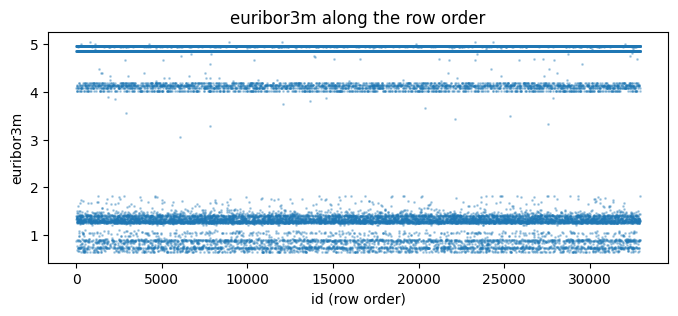

In [5]:
print(train[["id", "month", "euribor3m", "nr.employed"]].head(10))

print("\nCorrelation of id with time-related indicators:")
print(train[["id", "euribor3m", "nr.employed"]].corr()["id"].round(3))

fig, ax = plt.subplots(figsize=(8, 3))
ax.scatter(train["id"], train["euribor3m"], s=1, alpha=0.3)
ax.set_xlabel("id (row order)")
ax.set_ylabel("euribor3m")
ax.set_title("euribor3m along the row order")
plt.show()

**Row order.** The original file is in time order (May 2008 – Nov 2010), but here the rows are shuffled: the correlation of `id` with `euribor3m` is 0.002 and with `nr.employed` is −0.000, and the plot shows no trend. There is no year column, but the economic indicators act as a "clock" (euribor3m ≈ 4.9 before the crisis, ≈ 1 after). Since the instructor's split is random, I also use random **stratified** splits. In real use the model is trained on the past and used on the future, so random splits are optimistic (discussed in Stage 7).

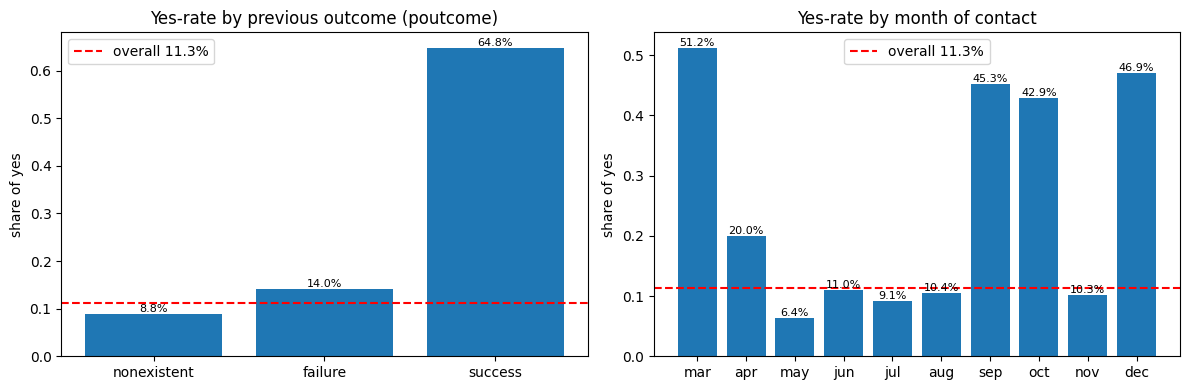

Yes-rate by poutcome:
 poutcome
nonexistent    0.088
failure        0.140
success        0.648
Name: y, dtype: float64

Number of calls per month:
 month
mar      457
apr     2089
may    10942
jun     4249
jul     5820
aug     4937
sep      453
oct      559
nov     3287
dec      147
Name: count, dtype: int64

Correlation of numeric features with y (1 = yes):
nr.employed      -0.356
pdays            -0.328
euribor3m        -0.308
emp.var.rate     -0.299
cons.price.idx   -0.134
campaign         -0.065
age               0.032
cons.conf.idx     0.058
previous          0.232
dtype: float64


In [6]:
y01 = (train["y"] == "yes").astype(int)   # 1 = yes, 0 = no
base_rate = y01.mean()

rate_pout = y01.groupby(train["poutcome"]).mean().sort_values()
# Plot 2: yes-rate by month
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
rate_month = y01.groupby(train["month"]).mean().reindex(month_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, rate, title in [(axes[0], rate_pout, "Yes-rate by previous outcome (poutcome)"),
                        (axes[1], rate_month, "Yes-rate by month of contact")]:
    bars = ax.bar(rate.index, rate.values)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in rate.values], fontsize=8)
    ax.axhline(base_rate, color="red", linestyle="--", label=f"overall {base_rate:.1%}")
    ax.set_ylabel("share of yes")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

print("Yes-rate by poutcome:\n", rate_pout.round(3))
print("\nNumber of calls per month:\n", train["month"].value_counts().reindex(month_order))

num_cols = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
print("\nCorrelation of numeric features with y (1 = yes):")
print(train[num_cols].corrwith(y01).sort_values().round(3))

**Which features relate to the answer.**
- **poutcome** (plot 1): clients who said *yes* in the previous campaign say *yes* again in **64.8 %** of cases, vs **14.0 %** after a failure and **8.8 %** for clients never contacted before (overall 11.3 %). This is one of the strongest signals.
- **month** (plot 2): most calls were made in May (10 942) with a yes-rate of only **6.4 %**, while rare months like March (457 calls) reach **51.2 %**. Months with few calls have much higher yes-rates.
- **Numeric features** (correlation with y): `nr.employed` −0.356, `pdays` −0.328, `euribor3m` −0.308, `emp.var.rate` −0.299, `previous` +0.232. The economic indicators are strongly related to the answer: more clients said *yes* when interest rates and employment were low (2009–2010). `age` (0.032) and `campaign` (−0.065) are weak on their own.

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = train.drop(columns=["id", "y", "duration"])
y = (train["y"] == "yes").astype(int)

assert list(X.columns) == [c for c in test.columns if c != "id"]

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("dev     :", X_dev.shape, " yes-rate:", round(y_dev.mean(), 4))
print("hold-out:", X_hold.shape, " yes-rate:", round(y_hold.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

dev     : (26352, 19)  yes-rate: 0.1127
hold-out: (6588, 19)  yes-rate: 0.1126


## Stage 3 · Validation design

- **Features.** `id` (just a row number), `y` (the target) and `duration` (leakage) are dropped. The remaining 19 columns are exactly the columns of `test.csv` without `id` (checked with `assert`).
- **Hold-out.** 20 % of `train.csv` (6 588 rows) is put aside with a stratified split (`random_state = SEED = 3042`). It is used **only once**, in Stage 7, after every choice has been made.
- **Cross-validation.** All comparison and tuning happen on the remaining 80 % (26 352 rows) with `StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`.
  - *Stratified*, because only 11.3 % are *yes*: every fold keeps the same share of *yes* (11.27 % dev vs 11.26 % hold-out).
  - *Shuffle*, because the rows are already in random order and the instructor's split is random too.
  - The **same `cv` object** is used for every model, so all models are scored on identical folds and their numbers can be compared fold by fold.
- **Fold spread.** For each model I report the mean **and** the standard deviation over the 5 folds. If two models differ by less than about one standard deviation, the difference is inside the noise and I do not call one of them better.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols and c != "pdays"]
print("categorical:", cat_cols)
print("numeric    :", num_cols, "+ pdays")

def make_preprocessor(unknown="category"):
    """unknown='category': keep 'unknown' as its own category.
       unknown='impute'  : treat 'unknown' as missing and fill with the most frequent value."""
    if unknown == "category":
        cat_step = OneHotEncoder(handle_unknown="ignore")
    else:
        cat_step = Pipeline([
            ("impute", SimpleImputer(missing_values="unknown", strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ])
    pdays_step = Pipeline([
        ("sentinel", SimpleImputer(missing_values=999, strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ])
    return ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("pdays", pdays_step, ["pdays"]),
        ("cat", cat_step, cat_cols),
    ])

prep = make_preprocessor()
prep.fit(X_dev)
print("\ndev after preprocessing :", prep.transform(X_dev).shape)
print("test after preprocessing:", prep.transform(test.drop(columns=["id"])).shape)
print("median of real pdays learned from dev:", prep.named_transformers_["pdays"]["sentinel"].statistics_)

categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numeric    : ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'] + pdays

dev after preprocessing : (26352, 63)
test after preprocessing: (8236, 63)
median of real pdays learned from dev: [6.]


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

prep_results = {}
for option in ["category", "impute"]:
    pipe = Pipeline([
        ("prep", make_preprocessor(option)),
        ("model", LogisticRegression(max_iter=1000)),
    ])
    res = cross_validate(pipe, X_dev, y_dev, cv=cv,
                         scoring=["roc_auc", "average_precision"],
                         return_estimator=True)
    prep_results[option] = res
    auc, ap = res["test_roc_auc"], res["test_average_precision"]
    print(f"unknown = {option:8s} | ROC-AUC per fold: {np.round(auc, 4)}")
    print(f"{'':19s}| ROC-AUC {auc.mean():.4f} ± {auc.std():.4f} | AP {ap.mean():.4f} ± {ap.std():.4f}")

print("\nMean 'age' learned by the scaler in each fold:")
for i, est in enumerate(prep_results["category"]["estimator"], start=1):
    print(f"  fold {i}: {est.named_steps['prep'].named_transformers_['num'].mean_[0]:.4f}")
print(f"  whole dev set: {X_dev['age'].mean():.4f}")

unknown = category | ROC-AUC per fold: [0.7824 0.7989 0.7859 0.7997 0.8048]
                   | ROC-AUC 0.7943 ± 0.0086 | AP 0.4526 ± 0.0138
unknown = impute   | ROC-AUC per fold: [0.7825 0.7985 0.7879 0.7999 0.8078]
                   | ROC-AUC 0.7953 ± 0.0090 | AP 0.4528 ± 0.0132

Mean 'age' learned by the scaler in each fold:
  fold 1: 40.0319
  fold 2: 40.0621
  fold 3: 40.0896
  fold 4: 39.9886
  fold 5: 40.1368
  whole dev set: 40.0618


## Stage 4 · Preprocessing inside a pipeline

For the 10 categorical columns, I used One-Hot Encoding with `handle_unknown="ignore"`. This method changes categories into numbers without creating an order between them. It also allows the model to work if a new category appears in `test.csv`.

I kept `"unknown"` values as a separate category because they may contain useful information. For example, 20.9% of the values in the `default` column are unknown. Instead of replacing them with other values, I kept this information.

For `pdays`, the value 999 means that the client was never contacted before. It is not a real number of days, so I replaced it with the median of the real values, which is 6 days. I also added a new column with 0 and 1 to show whether the client had never been contacted.

For the 8 numeric columns, I used `StandardScaler`. This is important because the values have different scales. For example, `nr.employed` is around 5000, while `previous` usually has values from 0 to 7. Scaling helps Logistic Regression, KNN, and SVM work better with these differences.

All preprocessing steps are inside one `Pipeline`. During cross-validation, the pipeline is fitted again on each training fold. This helps prevent data leakage. For example, the mean age learned by the scaler is slightly different in each fold: 40.03, 40.06, 40.09, 39.99, and 40.14. These values are different from the mean age of the full development set, which is 40.0618.

I also compared two ways of handling `"unknown"` values using Logistic Regression and the same five folds. Keeping `"unknown"` as a separate category gave a ROC-AUC of 0.7943 ± 0.0086 and an Average Precision of 0.4526 ± 0.0138. Replacing unknown values with the most frequent category gave a ROC-AUC of 0.7953 ± 0.0090 and an Average Precision of 0.4528 ± 0.0132.

The difference between the results is very small compared with the variation between folds. Therefore, both methods perform almost the same. I decided to keep `"unknown"` as a separate category because it is simple and preserves information about missing answers.

Finally, the pipeline can process the raw columns from `test.csv` without any extra manual preprocessing. I removed the `id` column before passing the data to the pipeline. The input has 8,236 rows and 19 columns, and after preprocessing, it has 8,236 rows and 63 columns.

In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer

def precision_top10(y_true, y_score):
    """Share of 'yes' among the 10 % of clients with the highest score."""
    k = int(np.ceil(0.10 * len(y_score)))
    top = np.argsort(-np.asarray(y_score), kind="stable")[:k]
    return np.asarray(y_true)[top].mean()

scoring = {
    "roc_auc": "roc_auc",
    "ap": "average_precision",
    "accuracy": "accuracy",
    "prec_top10": make_scorer(precision_top10, response_method="predict_proba"),
}

fold_scores = {}  

def evaluate(name, model, prep=None):
    """Same preprocessing, same folds, same metrics for every model."""
    pipe = Pipeline([("prep", prep if prep is not None else make_preprocessor()),
                     ("model", model)])
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=scoring)
    fold_scores[name] = res["test_roc_auc"]
    row = {"model": name}
    for m in scoring:
        row[m] = f"{res['test_' + m].mean():.4f} ± {res['test_' + m].std():.4f}"
    return row

rows = [
    evaluate("majority (always no)", DummyClassifier(strategy="most_frequent")),
    evaluate("logistic regression", LogisticRegression(max_iter=1000)),
]
summary = pd.DataFrame(rows).set_index("model")
summary

,roc_auc,ap,accuracy,prec_top10
model,,,,
majority (always no),0.5000 ± 0.0000,0.1127 ± 0.0001,0.8873 ± 0.0001,0.1096 ± 0.0051
logistic regression,0.7943 ± 0.0086,0.4526 ± 0.0138,0.8995 ± 0.0019,0.5028 ± 0.0151


## Stage 5 · Baselines

Same preprocessing, same 5 stratified folds, mean ± std over folds.

| Model | ROC-AUC | AP | Accuracy | Precision in top 10 % |
|---|---|---|---|---|
| Majority (always *no*) | 0.5000 ± 0.0000 | 0.1127 ± 0.0001 | 0.8873 ± 0.0001 | 0.1096 ± 0.0051 |
| Logistic regression | 0.7943 ± 0.0086 | 0.4526 ± 0.0138 | 0.8995 ± 0.0019 | 0.5028 ± 0.0151 |

**Accuracy is misleading.** The majority model reaches 88.73 % accuracy without finding a single buyer. Logistic regression adds only 1.2 points of accuracy, yet among the 10 % of clients it ranks highest, **50.3 %** say *yes* versus **11.0 %** for the majority model, about **4.6 times** better than calling at random. The ranking metrics show the real difference; accuracy hides it.

**The bar.** Every later model must beat logistic regression: ROC-AUC 0.7943 ± 0.0086 and precision in the top 10 % of 0.5028 ± 0.0151. A difference smaller than the fold spread (≈ 0.009 ROC-AUC) is treated as noise.

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

rows += [
    evaluate("decision tree (depth 5)",
             DecisionTreeClassifier(max_depth=5, random_state=SEED)),
    evaluate("random forest (300 trees)",
             RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                    n_jobs=-1, random_state=SEED)),
    evaluate("KNN (k = 50)",
             KNeighborsClassifier(n_neighbors=50)),
]
summary = pd.DataFrame(rows).set_index("model")
summary

,roc_auc,ap,accuracy,prec_top10
model,,,,
majority (always no),0.5000 ± 0.0000,0.1127 ± 0.0001,0.8873 ± 0.0001,0.1096 ± 0.0051
logistic regression,0.7943 ± 0.0086,0.4526 ± 0.0138,0.8995 ± 0.0019,0.5028 ± 0.0151
decision tree (depth 5),0.7745 ± 0.0107,0.4144 ± 0.0189,0.9000 ± 0.0020,0.5051 ± 0.0130
random forest (300 trees),0.7996 ± 0.0055,0.4705 ± 0.0101,0.8991 ± 0.0009,0.5290 ± 0.0127
KNN (k = 50),0.7822 ± 0.0107,0.4310 ± 0.0132,0.8989 ± 0.0022,0.4930 ± 0.0083
